In [1]:
import torch

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from lib_pca.distributional_pca import DistributionalPCA
from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov

## Example of Niculae

In [2]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))

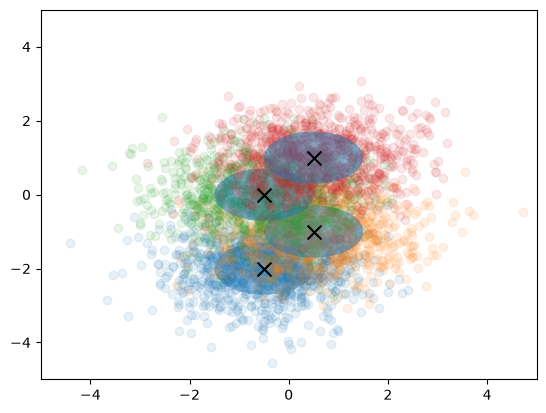

In [3]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

### Comparison of different PCA

In [4]:
# PCA on the means (as tested in the paper)
pca_means = PCA()
pca_means.fit(means)
eigenvectors_means = pca_means.components_

# PCA on the samples
pca_samples = PCA()
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)
pca_samples.fit(concat_samples)
eigenvectors_samples = torch.from_numpy(pca_samples.components_)

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit(means, Sigmas)
eigenvectors_distributional = pca_distributional.components_# .numpy()

# Distributional PCA approximating the Covariances and Means
pca_distributional_samples = DistributionalPCA()
pca_distributional_samples.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional_samples = pca_distributional.components_# .numpy()

In [5]:
eigenvectors_distributional.shape

torch.Size([1, 2])

/tmp/ipykernel_91876/2633527885.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  pc1_means = ts[:, None] * eigenvectors_means[0][None] # +  means.mean(axis=0, keepdims=True)


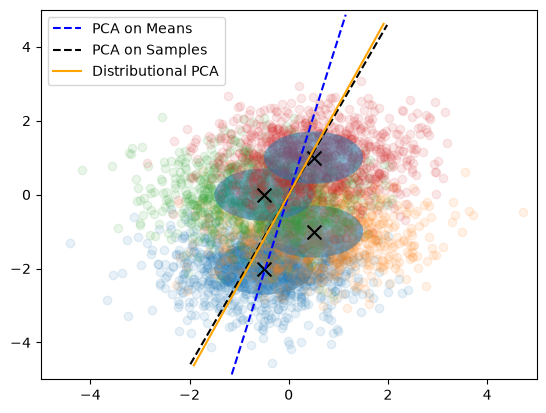

In [6]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k])

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

pc1_means = ts[:, None] * eigenvectors_means[0][None] # +  means.mean(axis=0, keepdims=True) 
plt.plot(pc1_means[:,0], pc1_means[:,1], "--", c="b", label="PCA on Means")

pc1_samples = ts[:, None] * eigenvectors_samples[0][None] # +  samples.mean(axis=0, keepdims=True) 
plt.plot(pc1_samples[:,0], pc1_samples[:,1], "--", c="k", label="PCA on Samples")

pc1_distributional = ts[:, None] * eigenvectors_distributional[0][None]
plt.plot(pc1_distributional[:,0], pc1_distributional[:,1], c="orange", label="Distributional PCA")

# pc1_distributional_samples = ts[:, None] * eigenvectors_distributional_samples[0][None]
# plt.plot(pc1_distributional_samples[:,0], pc1_distributional_samples[:,1], c="red", label="Distributional PCA (samples)")


plt.xlim(-5, 5)
plt.ylim(-5, 5)

plt.legend()
plt.show()